# Sesión 9 · De ARIMA a SARIMA

## Ruta acompañada

Este cuaderno explica cómo incorporar una estacionalidad repetitiva dentro de ARIMA. Trabajaremos con los totales mensuales de pasajeros internacionales entre 1949 y 1960, expresados en miles de pasajeros.

La pregunta central es:

> ¿Qué parte de la serie depende de los meses recientes y qué parte depende del mismo mes de años anteriores?

**Producto:** cuaderno ejecutado y ficha de decisión de una página.

### Objetivos

Al terminar podrás:

1. distinguir la parte regular y la parte estacional de SARIMA;
2. interpretar los parámetros `(p,d,q)(P,D,Q,m)`;
3. aplicar una diferencia estacional sin confundirla con una primera diferencia;
4. comparar SARIMA con referentes y métodos ya estudiados;
5. justificar una elección mediante validación y residuos.

La serie procede del conjunto `AirPassengers` del paquete `datasets` de R. Fuente: https://search.r-project.org/R/refmans/datasets/html/AirPassengers.html

## 0. Preparación

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#007FA3"
NARANJA = "#E57200"
VERDE = "#4F8F3A"
ROJO = "#C4473A"

In [2]:
ARCHIVO = Path("Datos_Sesion_9_Pasajeros_Aereos_1949_1960.csv")

if not ARCHIVO.exists():
    try:
        from google.colab import files
        print("Carga el archivo CSV proporcionado para la sesión")
        subidos = files.upload()
        ARCHIVO = Path(next(iter(subidos)))
    except Exception as exc:
        raise FileNotFoundError("No se encontró el archivo de datos.") from exc

datos = pd.read_csv(ARCHIVO, parse_dates=["fecha"])
serie = (datos.sort_values("fecha")
              .set_index("fecha")["pasajeros_miles"]
              .astype(float)
              .asfreq("MS"))

if serie.isna().any():
    raise ValueError("La serie tiene meses faltantes o valores vacíos.")

print(f"Observaciones: {len(serie)}")
print(f"Periodo: {serie.index.min().date()} a {serie.index.max().date()}")
display(serie.head().to_frame("pasajeros_miles"))

Observaciones: 144
Periodo: 1949-01-01 a 1960-12-01


,pasajeros_miles
fecha,
1949-01-01,112.000
1949-02-01,118.000
1949-03-01,132.000
1949-04-01,129.000
1949-05-01,121.000


In [3]:
def metricas(real, pronostico):
    real = np.asarray(real, dtype=float)
    pronostico = np.asarray(pronostico, dtype=float)
    error = real - pronostico
    denominador = np.abs(real) + np.abs(pronostico)
    smape = np.mean(np.where(denominador == 0, 0, 2 * np.abs(error) / denominador)) * 100
    return {
        "ME": error.mean(),
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "sMAPE_%": smape,
    }

def ingenuo_estacional(entrenamiento, indice_futuro, m=12):
    patron = entrenamiento.iloc[-m:].to_numpy()
    valores = np.resize(patron, len(indice_futuro))
    return pd.Series(valores, index=indice_futuro)

# 1. Reconocimiento del patrón

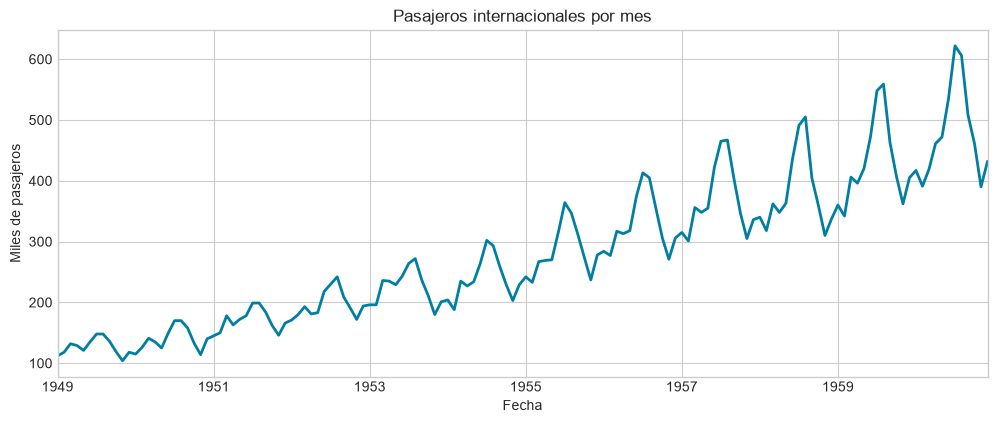

,mean,min,max
Ene,241.800,112.000,417.000
Feb,235.000,118.000,391.000
Mar,270.200,132.000,419.000
Abr,267.100,129.000,461.000
May,271.800,121.000,472.000
Jun,311.700,135.000,535.000
Jul,351.300,148.000,622.000
Ago,351.100,148.000,606.000
Sep,302.400,136.000,508.000
Oct,266.600,119.000,461.000


In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
serie.plot(ax=ax, color=AZUL, linewidth=2)
ax.set(title="Pasajeros internacionales por mes", xlabel="Fecha", ylabel="Miles de pasajeros")
plt.show()

tabla_mes = serie.groupby(serie.index.month).agg(["mean", "min", "max"])
tabla_mes.index = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
display(tabla_mes.round(1))

**Escribe tu interpretación.** Describe tendencia, estacionalidad, amplitud y cualquier observación inusual.

---

### Lo que veo en la serie

La gráfica cuenta una historia bastante clara. En 1949 los pasajeros se mueven alrededor de 120 o 140 mil, pero al llegar a 1960 los picos ya superan los 600 mil. El crecimiento se va acelerando, por eso la distancia entre los meses altos y los meses bajos también aumenta con los años.

El calendario se nota muchísimo. Julio y agosto son los meses de mayor movimiento, mientras que noviembre y febrero suelen estar entre los más bajos. No parece que haya un dato aislado que rompa la tendencia. Más bien se repite el mismo patrón cada año, pero en un nivel cada vez mayor.

Para mí, esto explica dos decisiones del modelo. El ciclo anual justifica usar `m = 12` y la amplitud creciente hace razonable probar el logaritmo. El comportamiento tiene sentido si pensamos en el crecimiento de la aviación comercial y en los viajes de verano. No trataría esos picos como valores atípicos.

# 2. El periodo estacional m

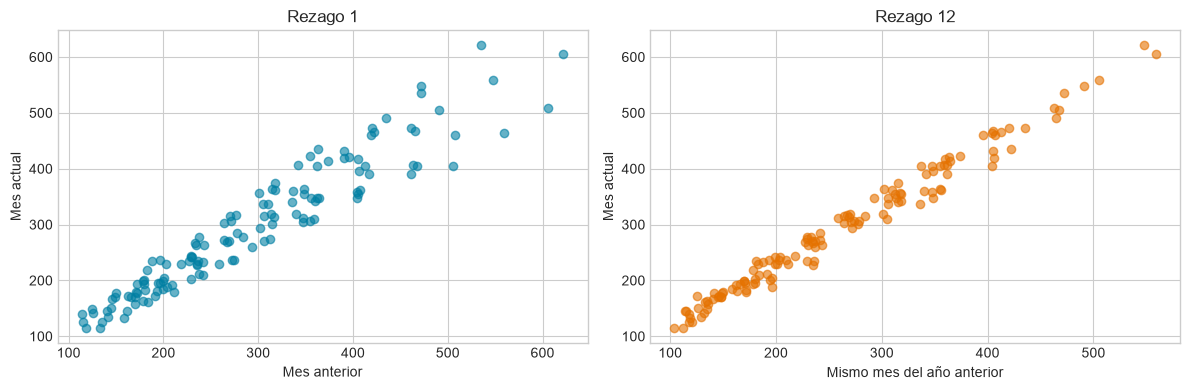

Correlación lag 1: 0.954
Correlación lag 12: 0.991


In [5]:
M = 12
rezagos = pd.DataFrame({
    "actual": serie,
    "mes_anterior_lag_1": serie.shift(1),
    "mismo_mes_anio_anterior_lag_12": serie.shift(M),
}).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(rezagos["mes_anterior_lag_1"], rezagos["actual"], alpha=.60, color=AZUL)
ax[0].set(title="Rezago 1", xlabel="Mes anterior", ylabel="Mes actual")
ax[1].scatter(rezagos["mismo_mes_anio_anterior_lag_12"], rezagos["actual"], alpha=.60, color=NARANJA)
ax[1].set(title="Rezago 12", xlabel="Mismo mes del año anterior", ylabel="Mes actual")
plt.tight_layout(); plt.show()

print("Correlación lag 1:", round(rezagos[["actual","mes_anterior_lag_1"]].corr().iloc[0,1], 3))
print("Correlación lag 12:", round(rezagos[["actual","mismo_mes_anio_anterior_lag_12"]].corr().iloc[0,1], 3))

En una serie mensual con ciclo anual, `m=12`. Esto no significa que el modelo use doce parámetros. Significa que una vuelta completa del patrón contiene doce observaciones.

- Datos diarios con ciclo semanal: `m=7`.
- Datos trimestrales con ciclo anual: `m=4`.
- Datos mensuales con ciclo anual: `m=12`.

El valor de `m` proviene del contexto y de la frecuencia de los datos; no debe elegirse solo porque una gráfica se vea mejor.

# 3. Diferencia regular y diferencia estacional

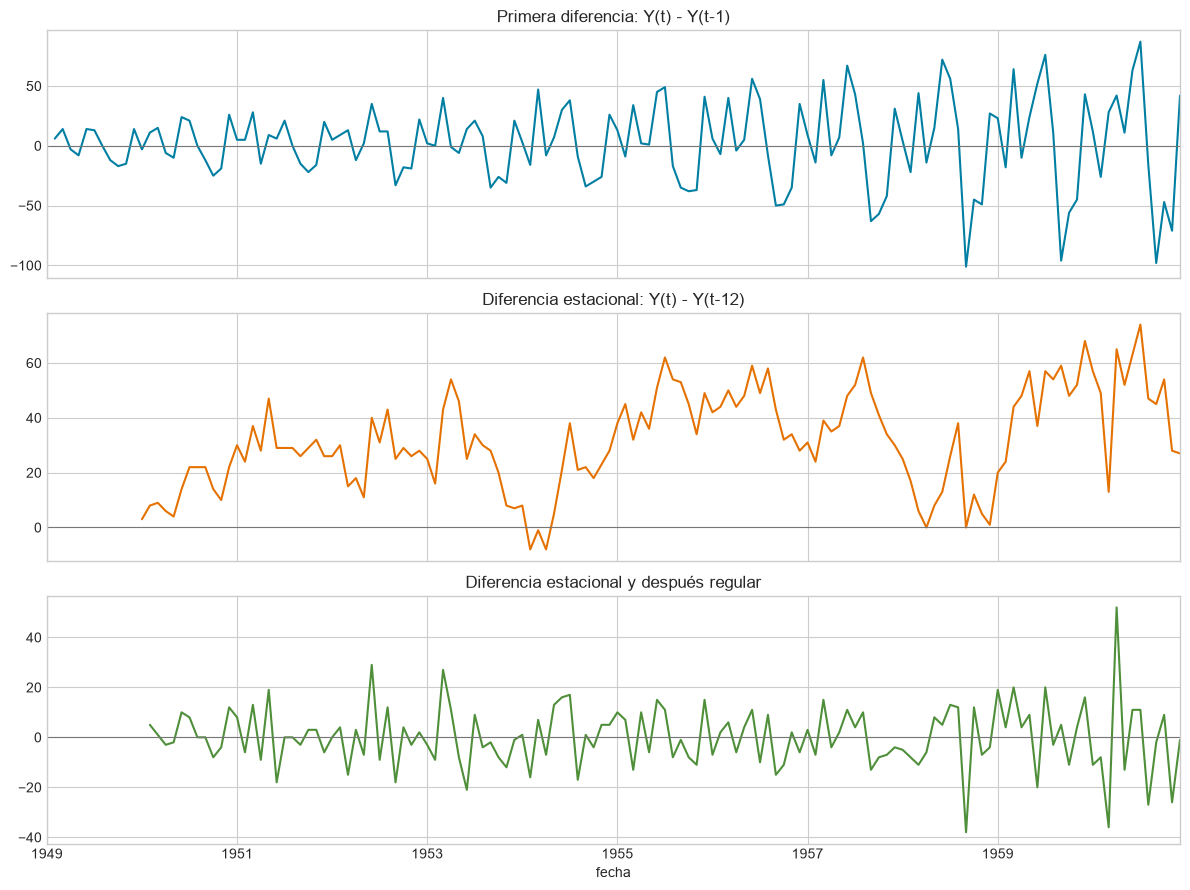

In [6]:
diferencia_regular = serie.diff(1)
diferencia_estacional = serie.diff(12)
doble_diferencia = serie.diff(12).diff(1)

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
diferencia_regular.plot(ax=ax[0], color=AZUL, title="Primera diferencia: Y(t) - Y(t-1)")
diferencia_estacional.plot(ax=ax[1], color=NARANJA, title="Diferencia estacional: Y(t) - Y(t-12)")
doble_diferencia.plot(ax=ax[2], color=VERDE, title="Diferencia estacional y después regular")
for a in ax: a.axhline(0, color="#777777", linewidth=.8)
plt.tight_layout(); plt.show()

**Explica con tus palabras.** ¿Qué patrón elimina la diferencia estacional y qué cambia al aplicar después la diferencia regular?

---

### Lo que entendí de las diferencias

Estas dos operaciones no hacen lo mismo:

- `Y(t) - Y(t-1)` pregunta cuánto cambió el número de pasajeros desde el mes anterior.
- `Y(t) - Y(t-12)` pregunta cuánto cambió respecto al mismo mes del año pasado.

La segunda me parece la más útil para esta serie, porque compara meses que tienen una posición parecida dentro del año. Por ejemplo, compara julio con julio y no julio con junio. Así se reduce el efecto de las vacaciones y queda más visible el cambio entre un año y otro.

La diferencia regular ayuda después. Aunque ya se haya quitado buena parte del ciclo anual, la serie sigue creciendo con el paso de los años. Al aplicar también la diferencia de un periodo, esa subida se transforma en variaciones alrededor de cero. La doble diferencia no busca borrar información sin más, sino dejar una señal más estable para que el modelo pueda trabajar.

Tampoco la confundí con quitar los promedios de cada mes. Aquí la operación se hace directamente con el rezago 12 de la serie y queda representada por `D = 1`.

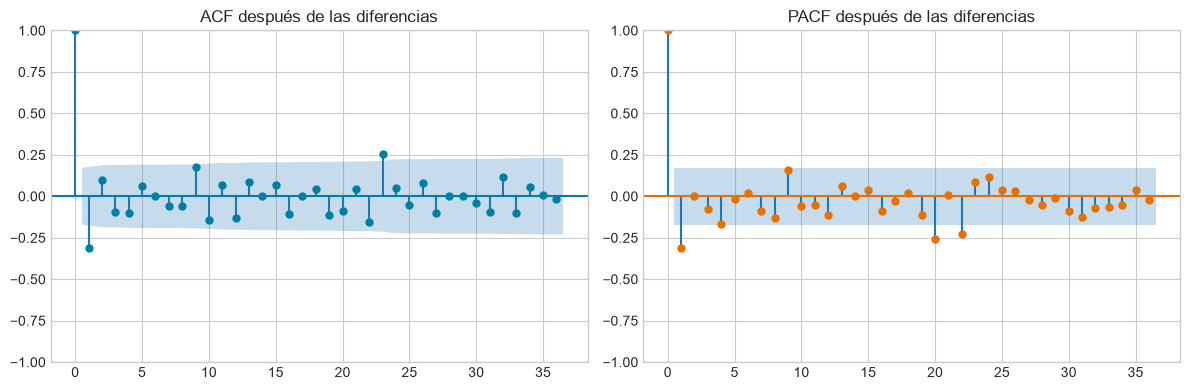

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(doble_diferencia.dropna(), lags=36, ax=ax[0], color=AZUL)
plot_pacf(doble_diferencia.dropna(), lags=36, ax=ax[1], method="ywm", color=NARANJA)
ax[0].set_title("ACF después de las diferencias")
ax[1].set_title("PACF después de las diferencias")
plt.tight_layout(); plt.show()

# 4. Lectura de SARIMA

La notación completa es:

`SARIMA(p,d,q)(P,D,Q,m)`

| Símbolo | Parte | Pregunta sencilla |
|---|---|---|
| `p` | AR regular | ¿Cuántos periodos recientes ayudan directamente? |
| `d` | Diferencia regular | ¿Cuántas veces se transforma el nivel en cambio reciente? |
| `q` | MA regular | ¿Cuántos errores recientes ayudan a corregir el pronóstico? |
| `P` | AR estacional | ¿Ayuda el valor de temporadas anteriores? |
| `D` | Diferencia estacional | ¿Se compara cada periodo con el mismo periodo del ciclo anterior? |
| `Q` | MA estacional | ¿Ayudan los errores de temporadas anteriores? |
| `m` | Periodicidad | ¿Cuántas observaciones forman un ciclo completo? |

Ejemplo: `SARIMA(0,1,1)(0,1,1,12)` usa una diferencia regular, una diferencia anual, un término MA reciente y un término MA anual.

# 5. Separación temporal

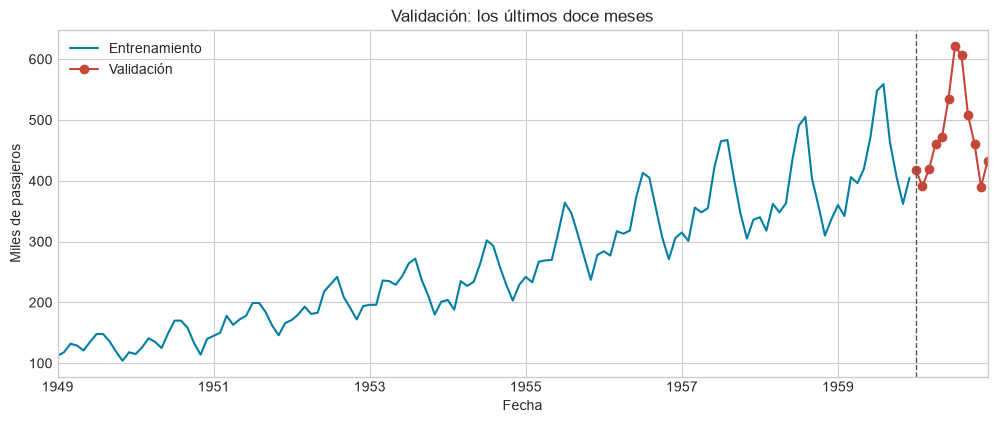

In [8]:
HORIZONTE = 12
entrenamiento = serie.iloc[:-HORIZONTE]
validacion = serie.iloc[-HORIZONTE:]

fig, ax = plt.subplots(figsize=(12, 4.5))
entrenamiento.plot(ax=ax, color=AZUL, label="Entrenamiento")
validacion.plot(ax=ax, color=ROJO, marker="o", label="Validación")
ax.axvline(validacion.index[0], color="#555555", linestyle="--", linewidth=1)
ax.set(title="Validación: los últimos doce meses", xlabel="Fecha", ylabel="Miles de pasajeros")
ax.legend(); plt.show()

La validación representa la decisión real: con datos disponibles hasta diciembre de 1959, pronosticamos los doce meses de 1960. Todos los métodos compiten en exactamente los mismos meses.

# 6. Modelos candidatos

In [9]:
pronosticos = {}

# 1. Referencia sencilla
pronosticos["Ingenuo estacional"] = ingenuo_estacional(entrenamiento, validacion.index, m=12)

# 2. Método de suavizamiento ya estudiado
ajuste_hw = ExponentialSmoothing(
    entrenamiento,
    trend="add",
    seasonal="mul",
    seasonal_periods=12,
    initialization_method="estimated",
).fit(optimized=True)
pronosticos["Holt-Winters multiplicativo"] = ajuste_hw.forecast(HORIZONTE)

# La amplitud aumenta con el nivel. El logaritmo permite trabajar con cambios proporcionales.
log_entrenamiento = np.log(entrenamiento)

# 3. ARIMA sin componente estacional
ajuste_arima = SARIMAX(
    log_entrenamiento,
    order=(1,1,1),
    seasonal_order=(0,0,0,0),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)
pronosticos["ARIMA(1,1,1) + log"] = np.exp(ajuste_arima.forecast(HORIZONTE))

# 4 y 5. Dos candidatos SARIMA deliberadamente pequeños
candidatos_sarima = {
    "SARIMA(0,1,1)(0,1,1,12) + log": ((0,1,1), (0,1,1,12)),
    "SARIMA(1,1,0)(0,1,1,12) + log": ((1,1,0), (0,1,1,12)),
}
ajustes_sarima = {}
for nombre, (orden, orden_estacional) in candidatos_sarima.items():
    ajuste = SARIMAX(
        log_entrenamiento,
        order=orden,
        seasonal_order=orden_estacional,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    ajustes_sarima[nombre] = ajuste
    pronosticos[nombre] = np.exp(ajuste.forecast(HORIZONTE))

,ME,MAE,RMSE,sMAPE_%
Holt-Winters multiplicativo,-4.783,10.303,15.810,2.163
"SARIMA(0,1,1)(0,1,1,12) + log",-12.030,13.174,18.510,2.802
"SARIMA(1,1,0)(0,1,1,12) + log",-13.821,14.671,19.744,3.104
Ingenuo estacional,47.833,47.833,50.708,10.572
"ARIMA(1,1,1) + log",59.542,68.475,95.518,14.314


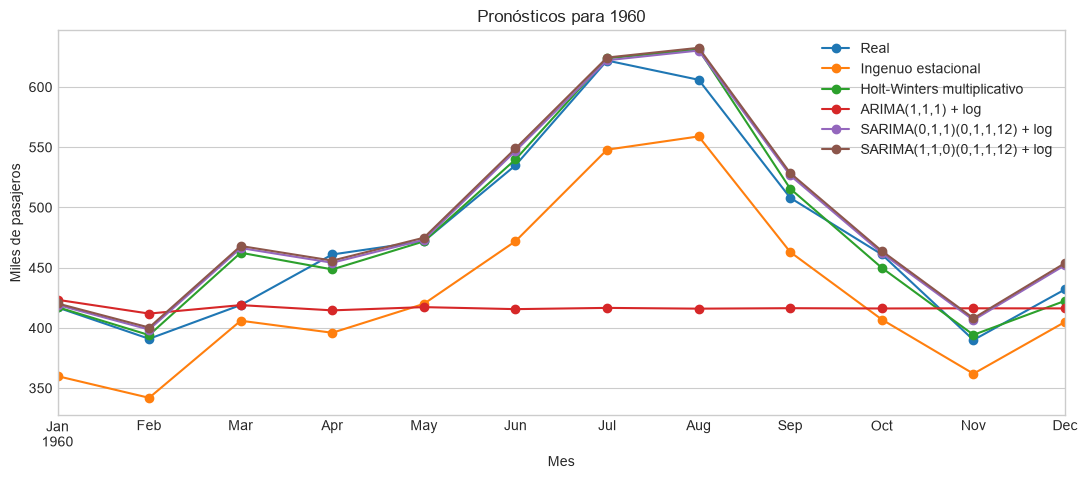

In [10]:
resultados = pd.DataFrame({
    nombre: metricas(validacion, pronostico)
    for nombre, pronostico in pronosticos.items()
}).T.sort_values("MAE")
display(resultados.round(3))

comparacion = pd.DataFrame({"Real": validacion, **pronosticos})
ax = comparacion.plot(figsize=(13, 5), marker="o")
ax.set(title="Pronósticos para 1960", xlabel="Mes", ylabel="Miles de pasajeros")
plt.show()

**Antes de elegir.** ¿Qué modelo logra el menor MAE? ¿SARIMA mejora al ARIMA no estacional? ¿Supera también a Holt-Winters?

---

### La comparación me dejó esto

| Puesto | Modelo | MAE | RMSE |
|---:|---|---:|---:|
| 1 | Holt-Winters multiplicativo | 10.303 | 15.810 |
| 2 | SARIMA(0,1,1)(0,1,1,12) + log | 13.174 | 18.510 |
| 3 | SARIMA(1,1,0)(0,1,1,12) + log | 14.671 | 19.744 |
| 4 | Ingenuo estacional | 47.833 | 50.708 |
| 5 | ARIMA(1,1,1) + log | 68.475 | 95.518 |

Lo más importante no fue que SARIMA quedara en primer lugar, porque no quedó. Holt-Winters tuvo el menor error y lo hizo por una diferencia relativamente pequeña. Lo importante fue que ambos métodos que sí consideran la estacionalidad funcionaron mucho mejor que el ARIMA sin ella y que el ingenuo estacional.

El ARIMA no estacional fue especialmente malo. Sus pronósticos se quedaron casi planos cerca de 416 mil pasajeros y no siguieron el comportamiento de los meses de verano. En cambio, el SARIMA pronosticó 622.2 mil para julio y el valor real fue 622 mil. Por eso considero que SARIMA es una buena opción, aunque en esta validación Holt-Winters fue ligeramente superior. También mantendría esa alternativa para comparar con más ventanas de validación.

### Por qué AIC no decide por sí solo

AIC ayuda a comparar modelos ajustados sobre la misma variable y con el mismo tratamiento de diferenciación. La validación responde una pregunta distinta: cuál pronosticó mejor observaciones posteriores.

En esta práctica elegimos con el error de validación y utilizamos AIC como evidencia complementaria entre candidatos comparables.

In [11]:
tabla_aic = pd.DataFrame({
    nombre: {"AIC": ajuste.aic, "BIC": ajuste.bic}
    for nombre, ajuste in ajustes_sarima.items()
}).T.sort_values("AIC")
display(tabla_aic.round(3))

,AIC,BIC
"SARIMA(1,1,0)(0,1,1,12) + log",-396.700,-388.710
"SARIMA(0,1,1)(0,1,1,12) + log",-392.990,-385.028


# 7. Diagnóstico del SARIMA

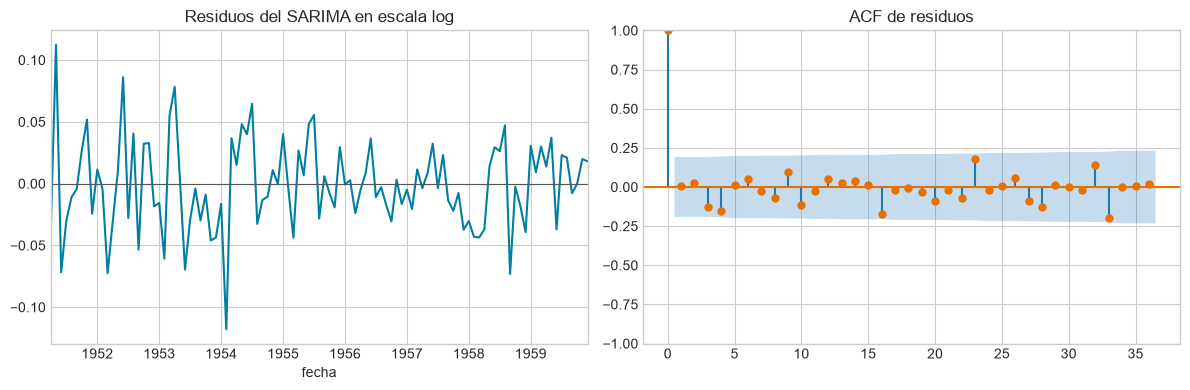

,lb_stat,lb_pvalue
12,8.491,0.581
24,18.753,0.660


In [12]:
nombre_sarima = "SARIMA(0,1,1)(0,1,1,12) + log"
ajuste_sarima = ajustes_sarima[nombre_sarima]

# Se descartan los residuos iniciales afectados por la inicialización del modelo.
inicio_util = max(ajuste_sarima.loglikelihood_burn, 13)
residuos = ajuste_sarima.resid.iloc[inicio_util:].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
residuos.plot(ax=ax[0], color=AZUL)
ax[0].axhline(0, color="#555555", linewidth=.8)
ax[0].set_title("Residuos del SARIMA en escala log")
plot_acf(residuos, lags=36, ax=ax[1], color=NARANJA)
ax[1].set_title("ACF de residuos")
plt.tight_layout(); plt.show()

diagnostico = acorr_ljungbox(residuos, lags=[12,24], model_df=2, return_df=True)
display(diagnostico.round(4))

**Interpreta el diagnóstico.** ¿Quedó autocorrelación visible? ¿Qué indican los p-valores de Ljung-Box?

---

### Mi lectura del diagnóstico

Aquí el resultado es tranquilizador. Los residuos no muestran una tendencia clara ni vuelven a dibujar el ciclo anual. También se mantienen alrededor de cero y la ACF no tiene picos preocupantes en los rezagos 12 y 24.

La prueba de Ljung-Box dio estos valores:

- Rezago 12: `p = 0.581`
- Rezago 24: `p = 0.661`

Con esos resultados no encuentro evidencia de autocorrelación que haya quedado sin explicar. La comparación con el ARIMA sin estacionalidad ayuda a verlo, porque ese modelo tenía p-valores cercanos a cero y todavía dejaba un patrón en los residuos.

No interpretaría esto como una garantía de que el modelo siempre va a acertar. Solo significa que, con esta prueba y estos datos, no quedó una señal temporal evidente. Un cambio fuerte en la economía, una crisis o una modificación en las rutas no aparece automáticamente en el modelo.

# 8. Incertidumbre del pronóstico

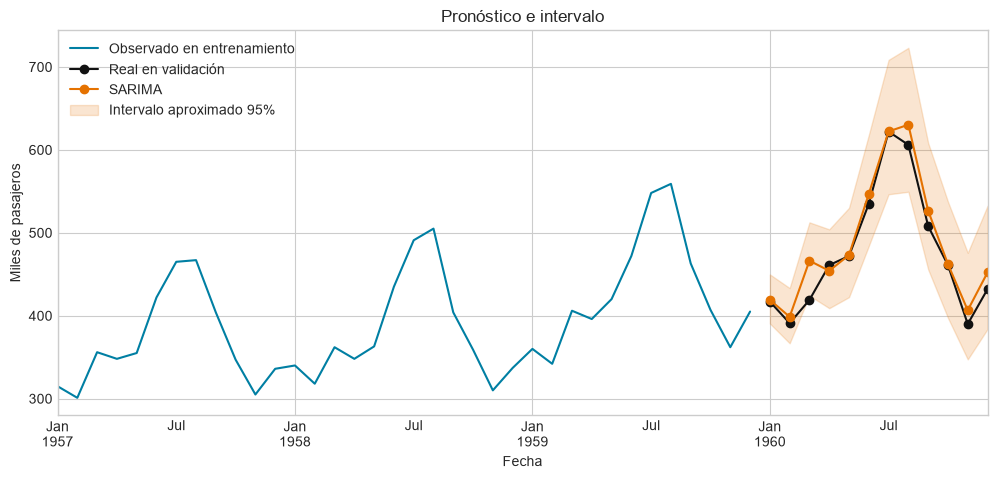

In [13]:
pred = ajuste_sarima.get_forecast(steps=HORIZONTE)
media = np.exp(pred.predicted_mean)
intervalo = np.exp(pred.conf_int(alpha=.05))

fig, ax = plt.subplots(figsize=(12, 5))
entrenamiento.iloc[-36:].plot(ax=ax, color=AZUL, label="Observado en entrenamiento")
validacion.plot(ax=ax, color="#111111", marker="o", label="Real en validación")
media.plot(ax=ax, color=NARANJA, marker="o", label="SARIMA")
ax.fill_between(intervalo.index, intervalo.iloc[:,0], intervalo.iloc[:,1], color=NARANJA, alpha=.18, label="Intervalo aproximado 95%")
ax.set(title="Pronóstico e intervalo", xlabel="Fecha", ylabel="Miles de pasajeros")
ax.legend(); plt.show()

El intervalo expresa incertidumbre bajo los supuestos del modelo. No garantiza que el valor real quede dentro y tampoco incorpora automáticamente crisis, cambios regulatorios o información externa.

# 9. Ficha de decisión

Entrega una página con:

1. **Problema y datos.** Variable, frecuencia, periodo y horizonte.
2. **Estacionalidad.** Evidencia del ciclo y justificación de `m`.
3. **Transformaciones.** Uso o rechazo de logaritmo, diferencia regular y diferencia estacional.
4. **Comparación.** Tabla de métricas y referente.
5. **Diagnóstico.** Qué indican residuos y Ljung-Box.
6. **Decisión.** Modelo elegido, utilidad y principal limitación.

Plantilla breve:

> Para pronosticar __________ a un horizonte de __________ utilizamos `m=____` porque __________. El modelo seleccionado fue __________, con un MAE de __________. Frente al referente __________. Los residuos indican __________. Esta decisión sería útil para __________, pero no incorpora __________.

### Rúbrica común

| Evidencia | Puntos |
|---|---:|
| Problema, frecuencia, horizonte y variable | 15 |
| Estacionalidad y elección de `m` | 20 |
| Transformaciones y candidatos justificados | 20 |
| Validación, métricas y referencia | 25 |
| Residuos, decisión y limitación | 20 |

### Fuentes de consulta

- Hyndman, R. J. y Athanasopoulos, G. *Forecasting: Principles and Practice*, sección de ARIMA estacional: https://otexts.com/fpp3/arima.html
- Documentación de `SARIMAX` en statsmodels: https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- Documentación del conjunto `AirPassengers`: https://search.r-project.org/R/refmans/datasets/html/AirPassengers.html